# Fracture Atlas · Bone fracture type classification
**A simple, reproducible EfficientNet-B0 training and deployment notebook.**

Dataset: [Shyam Gupta's 12-class X-ray dataset](https://www.kaggle.com/datasets/shyamgupta196/bone-fracture-split-classification).
In Colab, choose **Runtime → Change runtime type → T4 GPU**, then run all cells.

This is an educational classifier of **12 fracture types**, not a fracture/no-fracture detector or a diagnostic tool.
There is no normal class. Every input receives fracture-type scores, including unrelated images.
Model scores are not calibrated clinical probabilities. No patient-level identifiers are supplied, so patient-level independence cannot be established.


## What changed and why
The supplied EfficientNetV2-M notebook reached **50.29%** at epoch 9 and ended at **47.96%**, while training accuracy reached **89.24%**.
Its test set was reused for model selection, so those numbers are validation observations, not untouched test results.
The optional K-fold code also ignored its fold indices, training and evaluating on the same images.

This notebook uses a smaller EfficientNet-B0 as a practical candidate for the small dataset and browser deployment.
It removes exact pixel duplicates, holds out validation data from training, saves the best validation macro-F1 checkpoint,
and evaluates the supplied test split once. **A smaller model is not guaranteed to be more accurate.**
The new test result and old validation result use different protocols and cannot establish a fair model ranking.


In [ ]:
# Colab already supplies PyTorch and torchvision. Install the small extra tools.
%pip -q install kagglehub scikit-learn pandas matplotlib onnx onnxruntime


In [1]:
import os, json, random, hashlib, time, copy, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(8, os.cpu_count() or 2))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SIZE, BATCH = 224, 32
HEAD_EPOCHS, FINE_EPOCHS, FULL_EPOCHS, PATIENCE = 5, 9, 10, 5
OUT = Path('artifacts')
OUT.mkdir(exist_ok=True)
print(f'Device: {DEVICE} | image size: {SIZE} | seed: {SEED}')


Device: cpu | image size: 224 | seed: 42


## Download and audit the data
Class labels come directly from sorted training folders; the same order is exported for the website.
We hash decoded RGB pixels (not file names). Conflicting exact duplicates are excluded.
Within each class, only one copy of an image is kept. If a test image also occurs in training, training copies are removed.
This catches exact decoded duplicates, **not** all crops, resized copies, or repeated patient studies.
The supplied `test` folder is reserved for final evaluation. Any supplied `val` folder is unused; validation is derived from the cleaned training folder.


C:\Users\abood\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
                    Image audit
raw_images                 1686
cleaned_images             1398
excluded_images             288
conflicting_hashes          124
unreadable_images             0
train                       776
validation                  194
test                        428
                            Train  Validation  Test
name                                               
Avulsion fracture              74          18    42
Comminuted fracture           104          26    55
Compression-Crush fracture     77          19    36
Fracture Dislocation           86          21    47
Greenstick fracture            63          16    39
Hairline Fracture              65          16    37
Impacted fracture              50          13    30
Intra-articular fracture       51  

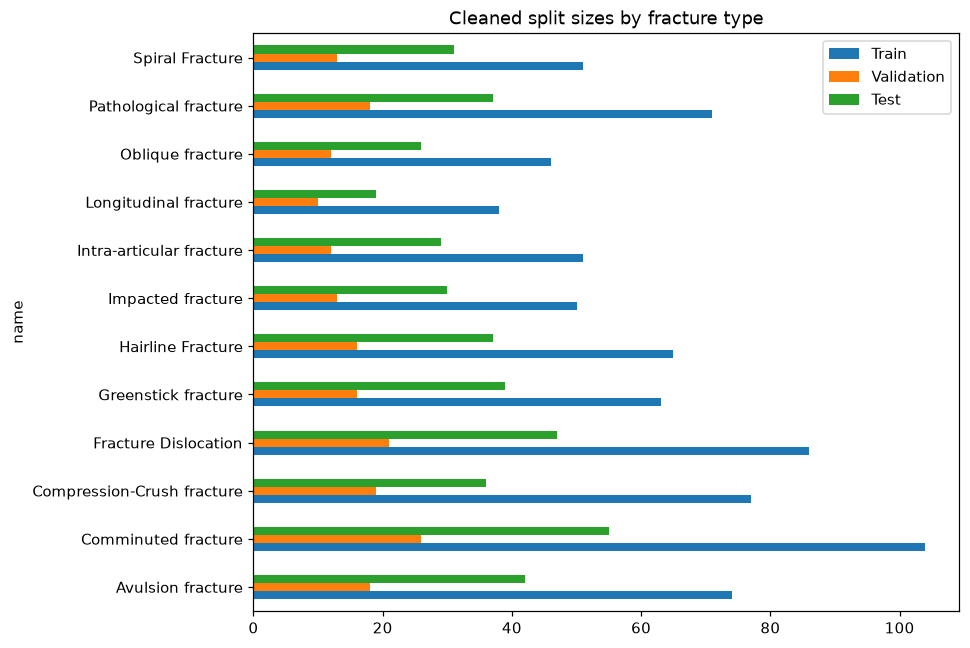

In [2]:
if os.environ.get('BONE_DATA_DIR'):
    data_root = Path(os.environ['BONE_DATA_DIR'])
else:
    import kagglehub
    data_root = Path(kagglehub.dataset_download('shyamgupta196/bone-fracture-split-classification/versions/1'))
candidates = [p.parent for p in data_root.rglob('train') if p.is_dir() and (p.parent / 'test').is_dir()]
if (data_root / 'train').is_dir() and (data_root / 'test').is_dir():
    candidates = [data_root]
if not candidates:
    raise FileNotFoundError('Expected train/ and test/ folders. Inspect the downloaded dataset.')
data_root = sorted(candidates, key=lambda p: len(p.parts))[0]
classes = sorted(p.name for p in (data_root / 'train').iterdir() if p.is_dir())
assert len(classes) == 12, f'Expected 12 fracture types, found {classes}'
assert classes == sorted(p.name for p in (data_root / 'test').iterdir() if p.is_dir())
rows, corrupt = [], []
for split in ['train', 'test']:
    for label, name in enumerate(classes):
        for path in sorted((data_root / split / name).rglob('*')):
            if path.suffix.lower() not in {'.png', '.jpg', '.jpeg', '.bmp', '.webp', '.tif', '.tiff'}:
                continue
            try:
                with Image.open(path) as im:
                    rgb = ImageOps.exif_transpose(im).convert('RGB')
                    digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
                rows.append(dict(path=str(path), label=label, name=name, split=split, hash=digest))
            except Exception as exc:
                corrupt.append(dict(path=str(path), error=str(exc)))
raw = pd.DataFrame(rows)
if raw.empty:
    raise ValueError('No readable images found.')
conflicts = raw.groupby('hash').label.nunique()
conflict_hashes = set(conflicts[conflicts > 1].index)
clean = raw[~raw.hash.isin(conflict_hashes)].copy()
# Give the held-out test set precedence, then remove repeated pixels.
clean['priority'] = clean.split.map({'test': 0, 'train': 1})
clean = clean.sort_values(['priority', 'path']).drop_duplicates('hash')
pool = clean[clean.split == 'train'].copy()
test_df = clean[clean.split == 'test'].copy().reset_index(drop=True)
train_df, val_df = train_test_split(pool, test_size=0.2, stratify=pool.label, random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
assert set(train_df.hash).isdisjoint(val_df.hash)
assert set(pool.hash).isdisjoint(test_df.hash)
audit = dict(raw_images=len(raw), cleaned_images=len(clean), excluded_images=len(raw)-len(clean),
             conflicting_hashes=len(conflict_hashes), unreadable_images=len(corrupt),
             train=len(train_df), validation=len(val_df), test=len(test_df))
(OUT / 'audit.json').write_text(json.dumps(audit, indent=2))
display(pd.Series(audit, name='Image audit').to_frame())
counts = pd.DataFrame({s: frame.name.value_counts() for s, frame in
                      [('Train', train_df), ('Validation', val_df), ('Test', test_df)]}).fillna(0).astype(int)
display(counts.reindex(classes))
counts.reindex(classes).plot.barh(figsize=(9, 6), title='Cleaned split sizes by fracture type')
plt.tight_layout(); plt.show()


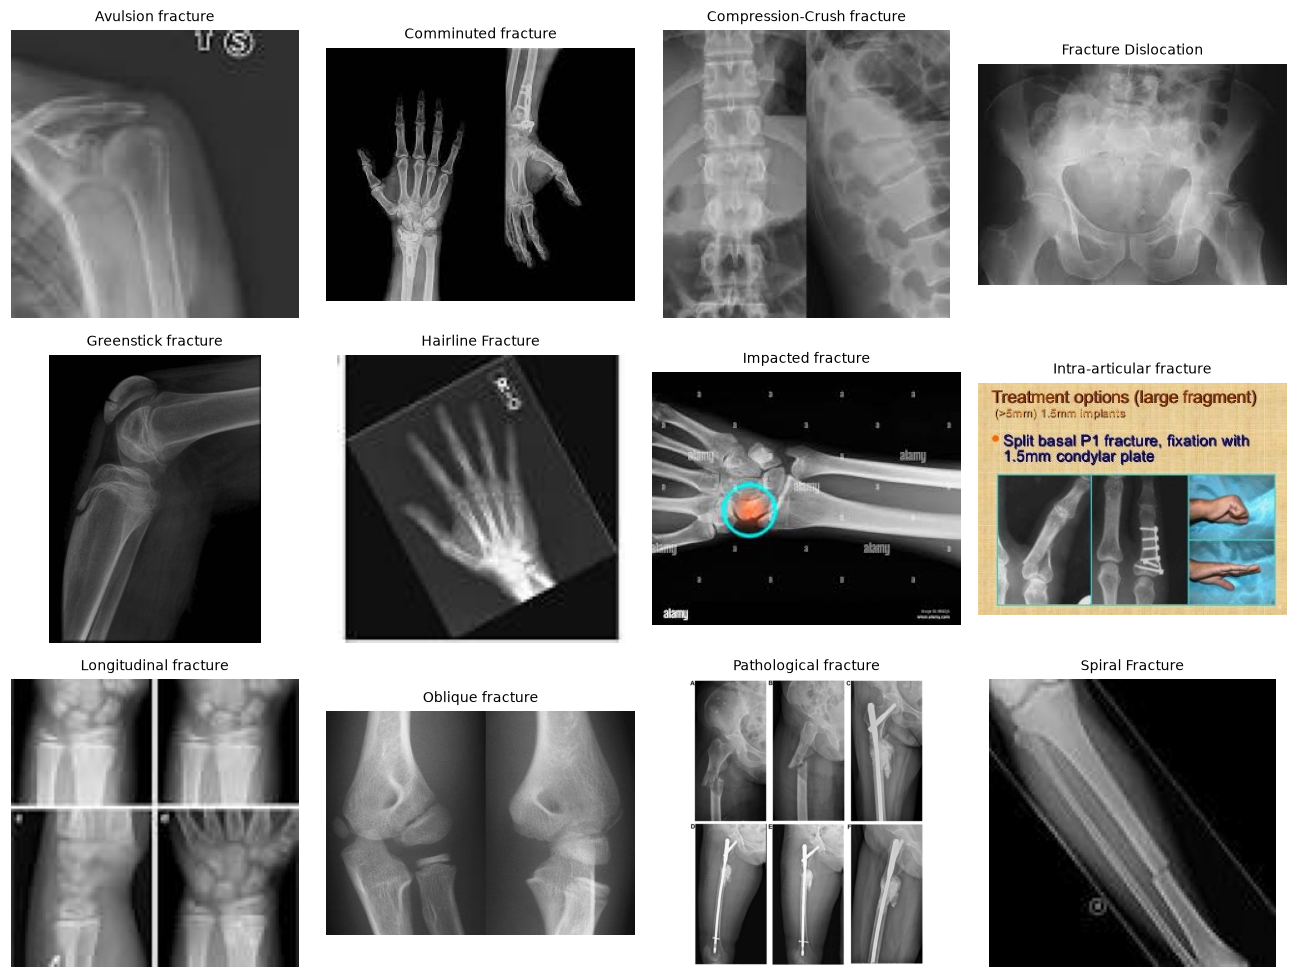

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
# Match the browser: EXIF orientation, RGB, square bilinear resize, ImageNet normalization.
# Mild augmentation avoids aggressive crops that could remove a fracture.
train_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, fill=0),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class Xrays(Dataset):
    def __init__(self, frame, transform):
        self.frame, self.transform = frame.reset_index(drop=True), transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        with Image.open(row.path) as im:
            image = ImageOps.exif_transpose(im).convert('RGB')
        return self.transform(image), int(row.label)

# num_workers=0 keeps this simple and works in Colab, Linux and Windows notebooks.
train_loader = DataLoader(Xrays(train_df, train_tf), batch_size=BATCH, shuffle=True, num_workers=0)
val_loader = DataLoader(Xrays(val_df, eval_tf), batch_size=BATCH, shuffle=False, num_workers=0)
test_loader = DataLoader(Xrays(test_df, eval_tf), batch_size=BATCH, shuffle=False, num_workers=0)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for label, ax in enumerate(axes.flat):
    row = train_df[train_df.label == label].iloc[0]
    with Image.open(row.path) as im:
        ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
    ax.set_title(classes[label], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()


## Train in three simple stages
First learn a new classifier with the ImageNet backbone frozen. Then fine-tune its last three feature blocks with a lower learning rate.
Finally, fine-tune the full backbone to let earlier features adapt to the X-ray domain. This continuation was chosen using validation results, before evaluating the test set.
Batch normalization statistics remain frozen to reduce noise on a small dataset. AdamW weight decay, label smoothing,
a validation-loss scheduler, and early stopping help control overfitting. Validation macro-F1 selects the checkpoint so every class matters.


In [4]:
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(model.classifier[1].in_features, len(classes)))
model = model.to(DEVICE)
for parameter in model.features.parameters():
    parameter.requires_grad = False
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
history, best_f1 = [], -1.0
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        for layer in model.modules():
            if isinstance(layer, nn.BatchNorm2d):
                layer.eval()
    total_loss, truth, predicted = 0.0, [], []
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)  # Keep [batch, classes], even when batch size is one.
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            truth.extend(labels.cpu().tolist())
            predicted.extend(logits.argmax(1).detach().cpu().tolist())
    return total_loss / len(loader.dataset), accuracy_score(truth, predicted), f1_score(
        truth, predicted, labels=list(range(len(classes))), average='macro', zero_division=0)

def fit(stage, epochs, learning_rate):
    global best_f1
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                 lr=learning_rate, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.5)
    stale = 0
    for epoch in range(epochs):
        started = time.time()
        tr_loss, tr_acc, tr_f1 = run_epoch(train_loader, optimizer)
        va_loss, va_acc, va_f1 = run_epoch(val_loader)
        scheduler.step(va_loss)
        row = dict(stage=stage, epoch=len(history)+1, train_loss=tr_loss, val_loss=va_loss,
                   train_accuracy=tr_acc, val_accuracy=va_acc, val_macro_f1=va_f1)
        history.append(row)
        improved = va_f1 > best_f1
        if improved:
            best_f1, stale = va_f1, 0
            torch.save({'state_dict': model.state_dict(), 'classes': classes, 'size': SIZE,
                        'validation_macro_f1': best_f1, 'epoch': row['epoch']}, OUT / 'best_model.pt')
        else:
            stale += 1
        pd.DataFrame(history).to_csv(OUT / 'history.csv', index=False)
        print(f'{stage} {epoch+1:02d}/{epochs}: train {tr_acc:.1%} | val {va_acc:.1%} | '
              f'val macro-F1 {va_f1:.3f} | {time.time()-started:.0f}s' + (' * best' if improved else ''), flush=True)
        if stale >= PATIENCE:
            print('Early stopping.'); break

if os.environ.get('BONE_RESUME') == '1' and (OUT / 'best_model.pt').exists():
    # Optional local continuation; leave BONE_RESUME unset for a fresh Colab run.
    saved = torch.load(OUT / 'best_model.pt', map_location=DEVICE, weights_only=True)
    history = pd.read_csv(OUT / 'history.csv').to_dict('records')
    best_f1 = saved['validation_macro_f1']
    model.load_state_dict(saved['state_dict'])
    print('Resumed the completed head and partial fine-tuning stages from their saved checkpoint/history.')
    display(pd.DataFrame(history))
else:
    fit('Head', HEAD_EPOCHS, 1e-3)
    model.load_state_dict(torch.load(OUT / 'best_model.pt', map_location=DEVICE, weights_only=True)['state_dict'])
    for parameter in model.features[-3:].parameters():
        parameter.requires_grad = True
    fit('Fine tune', FINE_EPOCHS, 5e-5)
model.load_state_dict(torch.load(OUT / 'best_model.pt', map_location=DEVICE, weights_only=True)['state_dict'])
print('Restored best validation checkpoint.')


Parameters: 4,022,920
Resumed the completed head and partial fine-tuning stages from their saved checkpoint/history.
        stage  epoch  train_loss  ...  train_accuracy  val_accuracy  val_macro_f1
0        Head      1    2.419114  ...        0.167526      0.298969      0.202235
1        Head      2    2.126492  ...        0.336340      0.371134      0.275857
2        Head      3    1.978224  ...        0.413660      0.350515      0.271077
3        Head      4    1.896452  ...        0.449742      0.350515      0.301728
4        Head      5    1.805499  ...        0.471649      0.376289      0.316721
5   Fine tune      6    1.731494  ...        0.494845      0.386598      0.325133
6   Fine tune      7    1.600347  ...        0.548969      0.386598      0.323024
7   Fine tune      8    1.544619  ...        0.595361      0.381443      0.326661
8   Fine tune      9    1.457715  ...        0.641753      0.365979      0.325467
9   Fine tune     10    1.427522  ...        0.649485      0.38

In [5]:
# Reseed this stage so a saved local continuation follows the same random sequence.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
for parameter in model.features.parameters():
    parameter.requires_grad = True
# Full backpropagation needs more memory; use smaller batches on a CPU laptop.
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(4, os.cpu_count() or 2))
    train_loader = DataLoader(Xrays(train_df, train_tf), batch_size=8, shuffle=True, num_workers=0)
fit('Full fine tune', FULL_EPOCHS, 5e-5)
model.load_state_dict(torch.load(OUT / 'best_model.pt', map_location=DEVICE, weights_only=True)['state_dict'])
print('Restored final best validation checkpoint. Test data has not selected this model.')


C:\Users\abood\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Full fine tune 01/10: train 68.0% | val 41.2% | val macro-F1 0.347 | 258s
C:\Users\abood\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Full fine tune 02/10: train 75.6% | val 43.3% | val macro-F1 0.382 | 311s
C:\Users\abood\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Full fine tune 03/10: train 79.3% | val 48.5% | val macro-F1 0.440 | 231s * best
C:\Users\abood\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expres

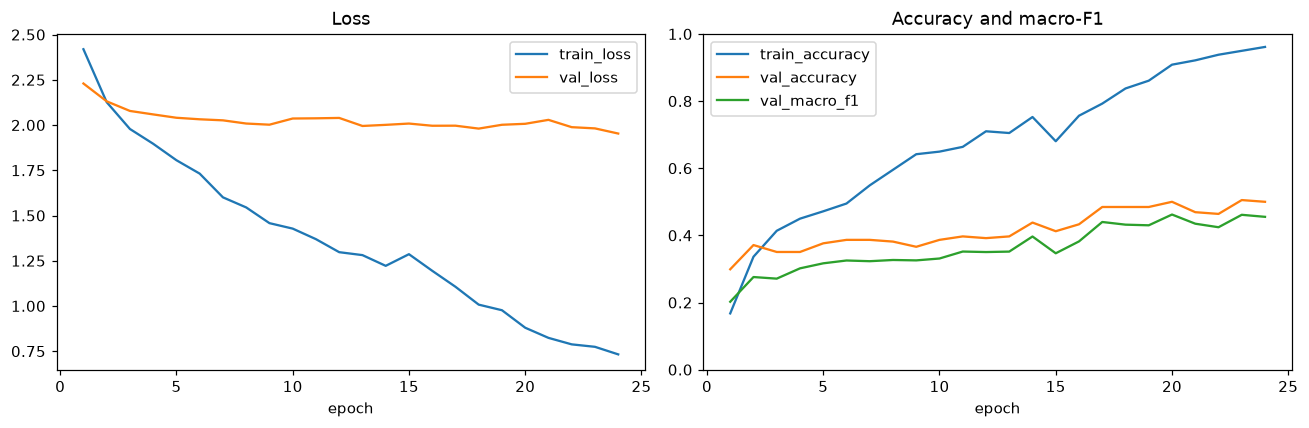

In [6]:
curves = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
curves.plot(x='epoch', y=['train_loss', 'val_loss'], ax=axes[0], title='Loss')
curves.plot(x='epoch', y=['train_accuracy', 'val_accuracy', 'val_macro_f1'], ax=axes[1], title='Accuracy and macro-F1')
axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(OUT / 'training_curves.png', dpi=150); plt.show()


## Final held-out evaluation
Run this after selecting the checkpoint. Do not tune the model using these results.
Report accuracy, balanced accuracy (mean class recall), macro-F1, per-class precision/recall, and a confusion matrix.
The bootstrap interval is image-based; it does not account for unknown patient correlations.


                            precision  recall  f1-score  support
Avulsion fracture               0.521   0.595     0.556   42.000
Comminuted fracture             0.578   0.473     0.520   55.000
Compression-Crush fracture      0.689   0.861     0.765   36.000
Fracture Dislocation            0.513   0.426     0.465   47.000
Greenstick fracture             0.667   0.564     0.611   39.000
Hairline Fracture               0.378   0.459     0.415   37.000
Impacted fracture               0.600   0.200     0.300   30.000
Intra-articular fracture        0.462   0.621     0.529   29.000
Longitudinal fracture           0.250   0.211     0.229   19.000
Oblique fracture                0.400   0.385     0.392   26.000
Pathological fracture           0.392   0.541     0.455   37.000
Spiral Fracture                 0.344   0.355     0.349   31.000
accuracy                        0.491   0.491     0.491    0.491
macro avg                       0.483   0.474     0.465  428.000
weighted avg             

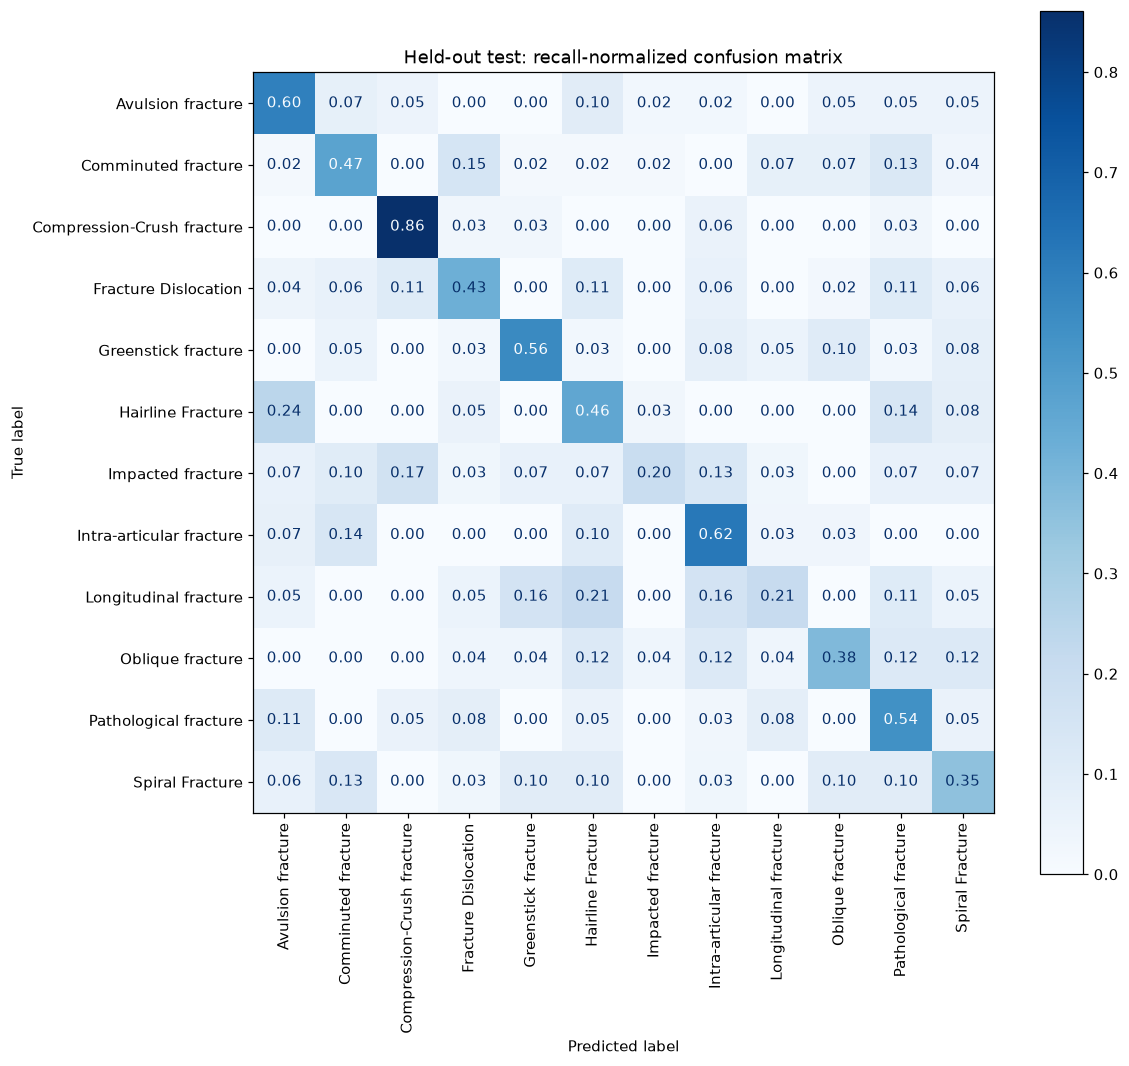

In [7]:
model.eval()
truth, probabilities = [], []
with torch.inference_mode():
    for images, labels in test_loader:
        probabilities.extend(model(images.to(DEVICE)).softmax(1).cpu().numpy())
        truth.extend(labels.numpy())
truth, probabilities = np.array(truth), np.array(probabilities)
pred = probabilities.argmax(1)
report = classification_report(truth, pred, labels=list(range(len(classes))), target_names=classes,
                               output_dict=True, zero_division=0)
table = pd.DataFrame(report).T
display(table.round(3))
table.to_csv(OUT / 'classification_report.csv')
rng = np.random.default_rng(SEED)
bootstrap = [accuracy_score(truth[idx], pred[idx]) for idx in
             (rng.integers(0, len(truth), len(truth)) for _ in range(2000))]
metrics = dict(model='EfficientNet-B0', test_accuracy=float(accuracy_score(truth, pred)),
               test_macro_f1=float(f1_score(truth, pred, labels=list(range(len(classes))), average='macro', zero_division=0)),
               test_balanced_accuracy=float(report['macro avg']['recall']),
               test_images=len(truth), accuracy_ci95=np.quantile(bootstrap, [0.025, 0.975]).tolist(),
               best_validation_macro_f1=best_f1, original_peak_validation_accuracy=0.5029,
               comparable_to_original=False, seed=SEED, audit=audit)
(OUT / 'metrics.json').write_text(json.dumps(metrics, indent=2))
print(f"Held-out accuracy: {metrics['test_accuracy']:.2%} | macro-F1: {metrics['test_macro_f1']:.3f}")
print('Original 50.29% was selected on the test folder; it is not a comparable untouched-test baseline.')
fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay.from_predictions(truth, pred, labels=list(range(len(classes))), display_labels=classes,
                                        normalize='true', xticks_rotation=90, ax=ax, cmap='Blues', values_format='.2f')
ax.set_title('Held-out test: recall-normalized confusion matrix')
plt.tight_layout(); plt.savefig(OUT / 'confusion_matrix.png', dpi=150); plt.show()


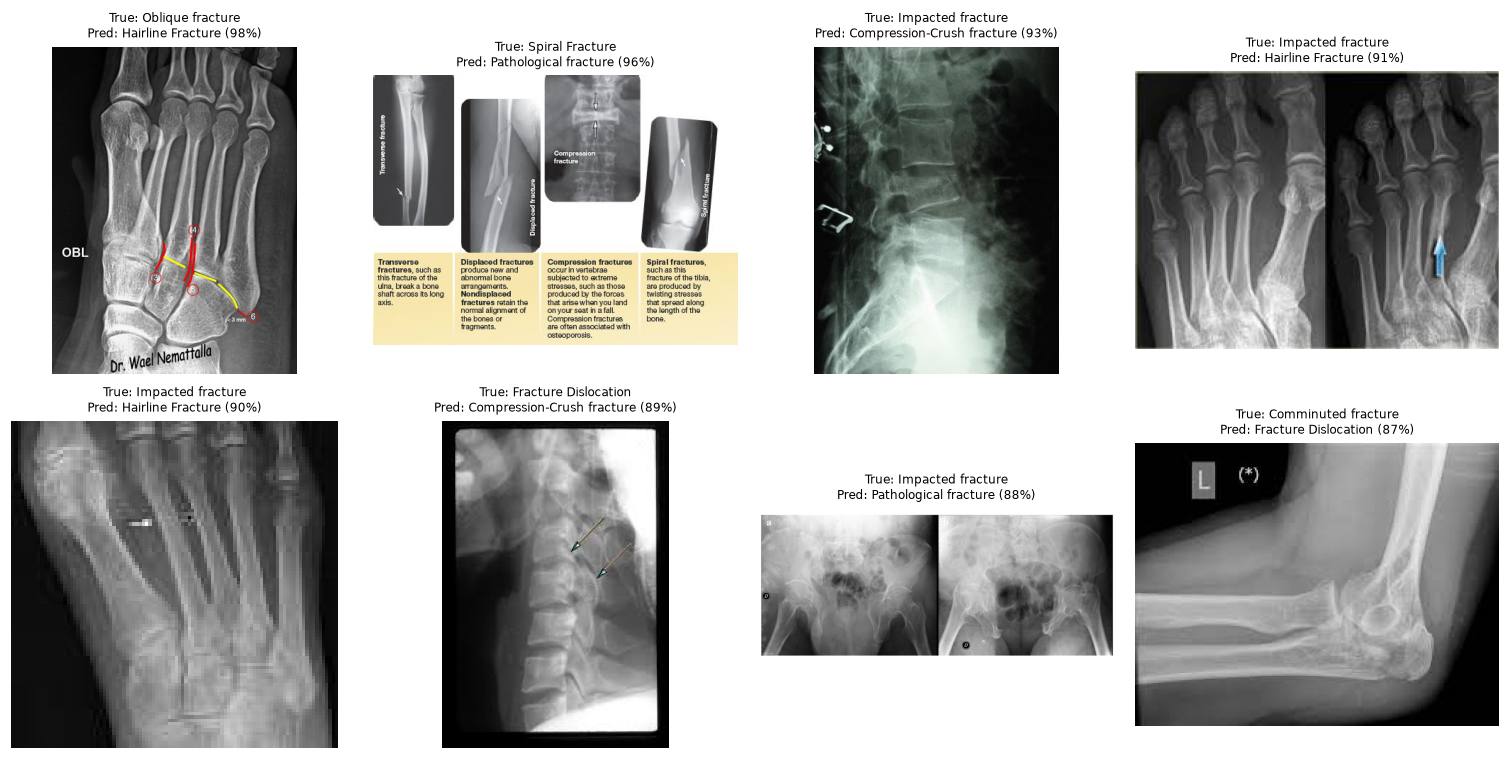

In [8]:
# Inspect mistakes, including confident errors. These scores are not calibrated.
wrong = np.flatnonzero(pred != truth)
order = wrong[np.argsort(-probabilities[wrong].max(1))][:8]
if len(order):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, order):
        with Image.open(test_df.iloc[i].path) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.set_title(f'True: {classes[truth[i]]}\nPred: {classes[pred[i]]} ({probabilities[i].max():.0%})', fontsize=8)
    plt.tight_layout(); plt.show()


## Export the browser model and sample X-rays
The exported model includes normalization and expects RGB float values in [0,1], shape [1,3,224,224].
The website does the same square resize. Canvas and Pillow interpolation can differ slightly; parity is checked on the same input tensor below.
ONNX is checked against PyTorch before packaging. Samples use seed 42 with five documented, visually reviewed replacements for non-radiographs or branded stock imagery. Selection does **not** use prediction correctness.
They are test examples already used in final evaluation, not new evidence. Review the dataset's license and image provenance before redistributing samples publicly.


In [9]:
import onnx, onnxruntime as ort
WEB = OUT / 'web'
(WEB / 'model').mkdir(parents=True, exist_ok=True)
(WEB / 'samples').mkdir(exist_ok=True)

class BrowserModel(nn.Module):
    def __init__(self, network):
        super().__init__()
        self.network = network
        self.register_buffer('mean', torch.tensor(MEAN).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(STD).view(1, 3, 1, 1))
    def forward(self, pixels):
        return self.network((pixels - self.mean) / self.std)

browser_model = BrowserModel(copy.deepcopy(model).cpu().eval()).eval()
dummy = torch.rand(1, 3, SIZE, SIZE)
onnx_path = WEB / 'model' / 'fracture.onnx'
torch.onnx.export(browser_model, dummy, str(onnx_path), input_names=['pixels'], output_names=['logits'],
                  opset_version=17, dynamo=False)
onnx.checker.check_model(str(onnx_path))
session = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
with torch.inference_mode():
    expected = browser_model(dummy).numpy()
actual = session.run(None, {'pixels': dummy.numpy()})[0]
np.testing.assert_allclose(expected, actual, rtol=1e-3, atol=1e-4)
parity = float(np.max(np.abs(expected - actual)))
print(f'ONNX export verified. Maximum logit difference: {parity:.6f}')
metadata = dict(classes=classes, size=SIZE, model='EfficientNet-B0', input='RGB float32 NCHW [0,1]',
                normalization='embedded', onnx_max_abs_error=parity, metrics=metrics)
(WEB / 'model' / 'metadata.json').write_text(json.dumps(metadata, indent=2))
# Five replacements selected by visual image-type review, without using predictions.
# The dataset also contains CT/MRI, illustrations and stock photos.
demo_overrides = {
    "Compression-Crush fracture": "d13bc49dbf0f3e8e84da87261d2acee570f8a7a666d288535761ee0f71573d15",
    "Greenstick fracture": "704a39e8f249be23ca249360f828788c1f24434aae783f4651c2dcf9419c8acf",
    "Hairline Fracture": "70604cd1101e77aa89ede4fd662bb13c3de4a621677a39b067649f8445acf550",
    "Longitudinal fracture": "d2b10693a483b550e096b9b1b61ef293c56d39d2e94d2bad672b21e3f33057e7",
    "Spiral Fracture": "008c0f84e8d9ec7852840226f73473cdc3797b0a9187fc1694e3d2f819ac2a97"
}
samples = []
for label, name in enumerate(classes):
    pool = test_df[test_df.label == label]
    if name in demo_overrides:
        pool = pool[pool.hash == demo_overrides[name]]
    assert len(pool), f'Reviewed sample missing for {name}; check dataset version 1.'
    row = pool.sample(1, random_state=SEED).iloc[0]
    filename = f'sample-{label:02d}.png'
    with Image.open(row.path) as im:
        rgb = ImageOps.exif_transpose(im).convert('RGB')
        rgb.thumbnail((800, 800))
        rgb.save(WEB / 'samples' / filename)
    samples.append(dict(file=f'samples/{filename}', label=name, source='Kaggle held-out test split',
                        source_hash=row.hash, selection='visual review' if name in demo_overrides else 'seed 42'))
(WEB / 'samples.json').write_text(json.dumps(samples, indent=2))
np.savez(OUT / 'test_predictions.npz', truth=truth, probabilities=probabilities)
with zipfile.ZipFile(OUT / 'browser-assets.zip', 'w', zipfile.ZIP_DEFLATED) as archive:
    for file in WEB.rglob('*'):
        if file.is_file():
            archive.write(file, file.relative_to(WEB))
print('Sample library: seed 42 with five visually reviewed radiograph replacements; predictions were not used.')
print('Ready: artifacts/browser-assets.zip. Extract into the project docs/ directory.')


notebook-cell-15:18: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
ONNX export verified. Maximum logit difference: 0.000001
Ready: artifacts/browser-assets.zip. Extract into the project docs/ directory.


Sample library: seed 42 with five visually reviewed radiograph replacements; predictions were not used.
Ready: artifacts/browser-assets.zip. Extract into the project docs/ directory.


In [10]:
# Download browser assets when running in Colab.
try:
    from google.colab import files
    files.download(str(OUT / 'browser-assets.zip'))
except ImportError:
    print('Local run: browser assets are in', WEB.resolve())


Local run: browser assets are in C:\Users\abood\Documents\Codex\2026-11-13\analyze-the-provided-notebook-which-is\outputs\Bone_Fracture_Classifier_Project\artifacts\web


## Next experiments
Keep the test set fixed. Compare EfficientNet-B0 and EfficientNetV2-S on identical training/validation data before claiming an architectural improvement.
Use patient-grouped splits if reliable patient IDs become available. Audit near duplicates, labels and image provenance.
For additional validation, use StratifiedKFold **on the cleaned training pool only** and construct each dataset using its actual fold indices.
Training five models is deliberately omitted from the simple default workflow.

## Author
- GitHub: [@AbdulrahmanAKh](https://github.com/AbdulrahmanAKh)
- LinkedIn: [Abdulrahman Alkhatib](https://www.linkedin.com/in/abdulrahman-alkhatib/)
- Email: [aboodkhatib90@gmail.com](mailto:aboodkhatib90@gmail.com)
- Portfolio: [abdulrahmanakh.github.io](https://abdulrahmanakh.github.io/)

---
<p align="center"><b>Developed &amp; Engineered by Abdulrahman Alkhatib</b><br>
<i>Computer Science Graduate | Software &amp; AI Engineer</i></p>

References: [PyTorch EfficientNet-B0](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html),
[ONNX Runtime Web](https://onnxruntime.ai/docs/tutorials/web/).
